# Hands-On P05 — Membangun dan Praproses Dataset Sensor
**Mata kuliah:** Edge Intelligence and Computing (CCE60306) · **Pertemuan 5**

Nama  : Rezky Auliasarie

NIM   : 245150300111014

Kelas : Edge Intelligence and Computing B

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.1.3


## 1. Memuat dan menginspeksi data

In [5]:
df = pd.read_csv("dataset_aktivitas_esp32.csv")
print(df.shape)
df.head()

(42015, 8)


,timestamp_ms,subjek,sesi,posisi,ax,ay,az,label
0,0,S01,1,pergelangan,0.223,0.002,1.063,diam
1,20,S01,1,pergelangan,0.102,0.190,0.925,diam
2,40,S01,1,pergelangan,-0.047,0.118,1.020,diam
3,60,S01,1,pergelangan,-0.050,0.115,0.986,diam
4,80,S01,1,pergelangan,0.049,0.058,1.168,diam


In [6]:
df.info()
print("\nNilai hilang per kolom:\n", df.isna().sum())
print("\nBaris duplikat:", df.duplicated().sum())
print("\nJumlah sampel per label:\n", df["label"].value_counts())
df[["ax", "ay", "az"]].describe().round(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42015 entries, 0 to 42014
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   timestamp_ms  42015 non-null  int64  
 1   subjek        42015 non-null  object 
 2   sesi          42015 non-null  int64  
 3   posisi        42015 non-null  object 
 4   ax            41918 non-null  float64
 5   ay            41918 non-null  float64
 6   az            41950 non-null  float64
 7   label         42015 non-null  object 
dtypes: float64(3), int64(2), object(3)
memory usage: 2.6+ MB

Nilai hilang per kolom:
 timestamp_ms     0
subjek           0
sesi             0
posisi           0
ax              97
ay              97
az              65
label            0
dtype: int64

Baris duplikat: 15

Jumlah sampel per label:
 label
diam     18008
jalan    18002
lari      6005
Name: count, dtype: int64


,ax,ay,az
count,41918.000,41918.000,41950.000
mean,-0.001,0.002,1.030
std,0.368,0.254,0.311
min,-1.608,-1.003,-8.000
25%,-0.203,-0.158,0.903
50%,-0.003,0.002,1.024
75%,0.202,0.159,1.146
max,1.591,1.086,15.900


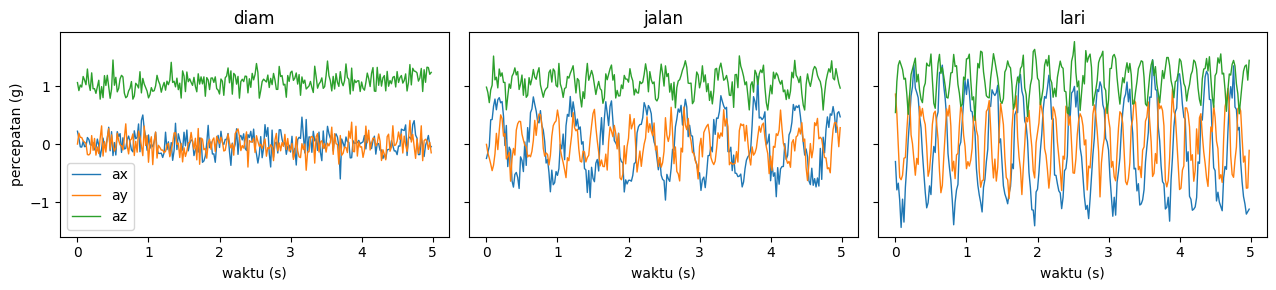

In [7]:
# Visualisasi sinyal satu subjek (5 detik pertama tiap aktivitas)
s = df[df.subjek == "S01"]
fig, axs = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for a, lab in zip(axs, ["diam", "jalan", "lari"]):
    seg = s[s.label == lab].head(250)
    for c in ["ax", "ay", "az"]:
        a.plot((seg.timestamp_ms - seg.timestamp_ms.iloc[0]) / 1000, seg[c], label=c, lw=1)
    a.set_title(lab); a.set_xlabel("waktu (s)")
axs[0].set_ylabel("percepatan (g)"); axs[0].legend(); plt.tight_layout(); plt.show()

## 2. Membersihkan data: duplikat dan nilai hilang

In [9]:
df = df.drop_duplicates().sort_values(["subjek", "sesi", "timestamp_ms"]).reset_index(drop=True)
# Interpolasi linier per rekaman (subjek+sesi) — cocok untuk deret waktu dengan celah pendek
axes = ["ax", "ay", "az"]
df[axes] = df.groupby(["subjek", "sesi"])[axes].transform(lambda g: g.interpolate(limit=10, limit_direction="both"))
print("Sisa nilai hilang:", int(df[axes].isna().sum().sum()), "| ukuran:", df.shape)

Sisa nilai hilang: 0 | ukuran: (42000, 8)


## 3. Mendeteksi *outlier*


Bandingkan metode statistik (IQR) dengan aturan domain. Ingat: pada data aktivitas, nilai besar saat *lari* adalah **wajar**, bukan *outlier*.

In [10]:
q1, q3 = df["az"].quantile([0.25, 0.75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
flag_iqr = (df["az"] < lo) | (df["az"] > hi)
print(f"Pagar IQR az: [{lo:.2f}, {hi:.2f}] -> {flag_iqr.sum()} titik ditandai")
print(flag_iqr.groupby(df.label).sum())      # banyak titik 'lari' ikut ditandai!

# Aturan domain: rentang sensor ±4 g -> nilai di luar itu pasti glitch
flag_dom = (df[axes].abs() > 4).any(axis=1)
print("Glitch menurut aturan domain:", int(flag_dom.sum()))
df.loc[flag_dom, axes] = np.nan
df[axes] = df.groupby(["subjek", "sesi"])[axes].transform(lambda g: g.interpolate(limit_direction="both"))

Pagar IQR az: [0.54, 1.51] -> 475 titik ditandai
label
diam      34
jalan     98
lari     343
Name: az, dtype: int64
Glitch menurut aturan domain: 25


## 4. *Windowing* dan ekstraksi fitur
Jendela W = 128 sampel (2,56 s pada 50 Hz) dengan langkah S = 64 (tumpang tindih 50%), seperti pada dataset UCI HAR.
Jumlah jendela per rekaman: N = ⌊(L − W)/S⌋ + 1.

In [11]:
W, S = 128, 64
def fitur(win):
    out = {}
    mag = np.sqrt((win[axes] ** 2).sum(axis=1))
    for c, v in list(win[axes].items()) + [("mag", mag)]:
        v = np.asarray(v)
        out.update({f"{c}_mean": v.mean(), f"{c}_std": v.std(), f"{c}_min": v.min(),
                    f"{c}_max": v.max(), f"{c}_rms": np.sqrt((v ** 2).mean())})
    return out

rows = []
for (subj, sesi), g in df.groupby(["subjek", "sesi"]):
    L = len(g); n_win = (L - W) // S + 1
    for k in range(n_win):
        w = g.iloc[k * S: k * S + W]
        r = fitur(w); r.update(subjek=subj, posisi=w.posisi.iloc[0], label=w.label.mode()[0]); rows.append(r)
feat = pd.DataFrame(rows)
print(feat.shape); feat.head()

(624, 23)


,ax_mean,ax_std,ax_min,ax_max,ax_rms,ay_mean,ay_std,ay_min,ay_max,ay_rms,...,az_max,az_rms,mag_mean,mag_std,mag_min,mag_max,mag_rms,subjek,posisi,label
0,0.012461,0.163047,-0.366,0.504,0.163522,-0.000211,0.151351,-0.395,0.351,0.151351,...,1.453,1.056086,1.070334,0.139100,0.796452,1.466444,1.079335,S01,pergelangan,diam
1,0.009734,0.182521,-0.600,0.467,0.182781,-0.019891,0.147559,-0.450,0.294,0.148894,...,1.435,1.096051,1.113005,0.134636,0.796452,1.467780,1.121119,S01,pergelangan,diam
2,0.017977,0.175954,-0.600,0.467,0.176870,-0.004750,0.158652,-0.450,0.409,0.158723,...,1.435,1.115152,1.132139,0.135288,0.814069,1.467780,1.140193,S01,pergelangan,diam
3,0.005945,0.156217,-0.334,0.474,0.156331,0.030188,0.165757,-0.352,0.436,0.168484,...,1.374,1.107195,1.123807,0.125557,0.835234,1.438764,1.130799,S01,pergelangan,diam
4,-0.004328,0.158823,-0.464,0.474,0.158882,0.025438,0.165742,-0.352,0.436,0.167683,...,1.343,1.074639,1.092274,0.123072,0.820408,1.375149,1.099186,S01,pergelangan,diam


## 5. *Encoding* fitur kategorikal

In [12]:
feat = pd.get_dummies(feat, columns=["posisi"], prefix="pos", dtype=int)
kelas = sorted(feat.label.unique()); peta = {k: i for i, k in enumerate(kelas)}
feat["y"] = feat.label.map(peta)
print(peta); feat.filter(like="pos_").head()

{'diam': 0, 'jalan': 1, 'lari': 2}


,pos_pergelangan,pos_pinggang
0,1,0
1,1,0
2,1,0
3,1,0
4,1,0


## 6. Membagi data **per subjek** (mencegah kebocoran)
Jendela yang tumpang tindih dari subjek yang sama sangat mirip. Jika dibagi acak, jendela 'kembar' bisa jatuh di train dan test sekaligus.

In [13]:
train_s, val_s, test_s = ["S01", "S02", "S03", "S04"], ["S05"], ["S06"]
Xcols = [c for c in feat.columns if c not in ("subjek", "label", "y")]
part = {n: feat[feat.subjek.isin(s)] for n, s in [("train", train_s), ("val", val_s), ("test", test_s)]}
for n, p in part.items(): print(n, p.shape, p.label.value_counts().to_dict())

train (416, 25) {'diam': 180, 'jalan': 180, 'lari': 56}
val (104, 25) {'diam': 45, 'jalan': 45, 'lari': 14}
test (104, 25) {'diam': 45, 'jalan': 45, 'lari': 14}


## 7. *Scaling*: `fit` hanya pada data latih

In [14]:
sc = StandardScaler().fit(part["train"][Xcols])
X = {n: sc.transform(p[Xcols]) for n, p in part.items()}
y = {n: p["y"].to_numpy() for n, p in part.items()}
print("rata-rata train ≈", X["train"].mean().round(3), "| std train ≈", X["train"].std().round(3))
print("rata-rata test  ≈", X["test"].mean().round(3), "(tidak harus 0)")

rata-rata train ≈ 0.0 | std train ≈ 1.0
rata-rata test  ≈ -0.089 (tidak harus 0)


## 8. Ketidakseimbangan kelas: SMOTE sederhana (hanya pada data latih)
x_baru = x_i + λ (x_zi − x_i), dengan x_zi salah satu k tetangga terdekat dari kelas yang sama (Chawla et al., 2002).

In [15]:
def smote(Xc, n_new, k=5, rng=np.random.default_rng(0)):
    d = ((Xc[:, None, :] - Xc[None, :, :]) ** 2).sum(-1)
    nn = np.argsort(d, axis=1)[:, 1:k + 1]
    i = rng.integers(0, len(Xc), n_new); j = nn[i, rng.integers(0, k, n_new)]
    lam = rng.random((n_new, 1))
    return Xc[i] + lam * (Xc[j] - Xc[i])

cnt = np.bincount(y["train"]); print("sebelum:", dict(zip(kelas, cnt.tolist())))
Xb, yb = [X["train"]], [y["train"]]
for c in range(len(kelas)):
    kurang = cnt.max() - cnt[c]
    if kurang > 0:
        Xb.append(smote(X["train"][y["train"] == c], kurang)); yb.append(np.full(kurang, c))
X_bal, y_bal = np.vstack(Xb), np.concatenate(yb)
print("sesudah:", dict(zip(kelas, np.bincount(y_bal).tolist())))

sebelum: {'diam': 180, 'jalan': 180, 'lari': 56}
sesudah: {'diam': 180, 'jalan': 180, 'lari': 180}


## 9. Uji cepat dengan model sederhana (pratinjau P6)
Keputusan memakai SMOTE atau tidak diambil berdasarkan **data validasi**, bukan data uji.

In [16]:
hasil = {}
for nama, (Xt, yt) in {"tanpa SMOTE": (X["train"], y["train"]), "dengan SMOTE": (X_bal, y_bal)}.items():
    m = KNeighborsClassifier(n_neighbors=5).fit(Xt, yt)
    f1v = f1_score(y["val"], m.predict(X["val"]), average="macro")
    pt = m.predict(X["test"])
    hasil[nama] = (f1v, m)
    print(f"{nama:13s} F1-makro validasi={f1v:.3f} | uji: akurasi={accuracy_score(y['test'], pt):.3f}, F1-makro={f1_score(y['test'], pt, average='macro'):.3f}")
terbaik = max(hasil, key=lambda k: hasil[k][0]); print("Dipilih berdasarkan validasi:", terbaik)
print(classification_report(y["test"], hasil[terbaik][1].predict(X["test"]), target_names=kelas))

tanpa SMOTE   F1-makro validasi=1.000 | uji: akurasi=0.904, F1-makro=0.871
dengan SMOTE  F1-makro validasi=1.000 | uji: akurasi=0.740, F1-makro=0.694
Dipilih berdasarkan validasi: tanpa SMOTE
              precision    recall  f1-score   support

        diam       1.00      1.00      1.00        45
       jalan       1.00      0.78      0.88        45
        lari       0.58      1.00      0.74        14

    accuracy                           0.90       104
   macro avg       0.86      0.93      0.87       104
weighted avg       0.94      0.90      0.91       104



## 10. Menyimpan dataset siap latih

In [17]:
np.savez("dataset_siap_latih.npz", X_train=X_bal, y_train=y_bal, X_val=X["val"], y_val=y["val"],
         X_test=X["test"], y_test=y["test"], fitur=np.array(Xcols), kelas=np.array(kelas),
         scaler_mean=sc.mean_, scaler_scale=sc.scale_)
print("tersimpan: dataset_siap_latih.npz")

tersimpan: dataset_siap_latih.npz


## Latihan
1. Ubah W menjadi 64 dan 256. Bagaimana jumlah jendela dan skor F1 berubah?
2. Ganti pembagian per subjek dengan `train_test_split` acak pada jendela. Mengapa skornya naik? Apakah skor itu jujur?
3. Coba `MinMaxScaler`. Apakah hasil KNN berubah?
4. Tulis *datasheet* ringkas (motivasi, komposisi, proses pengumpulan, praproses, penggunaan) untuk dataset ini.

1. Pengerjaan Nomor 1 (Mengubah Ukuran Jendela $W = 64$ dan $W = 256$)

In [29]:
# Nomor 1: Eksperimen Ukuran Jendela W
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, accuracy_score

def ekstraksi_fitur_window(df_input, W, step=None):
    if step is None:
        step = W // 2

    rows = []
    for (subjek, sesi), group in df_input.groupby(['subjek', 'sesi']):
        group = group.reset_index(drop=True)
        for start in range(0, len(group) - W + 1, step):
            win = group.iloc[start:start+W]
            label = win['label'].mode()[0]
            posisi = win['posisi'].mode()[0]

            r = {
                'subjek': subjek, 'sesi': sesi, 'posisi': posisi, 'label': label,
                'ax_mean': win['ax'].mean(), 'ax_std': win['ax'].std(),
                'ay_mean': win['ay'].mean(), 'ay_std': win['ay'].std(),
                'az_mean': win['az'].mean(), 'az_std': win['az'].std(),
                'vm_mean': np.sqrt(win['ax']**2 + win['ay']**2 + win['az']**2).mean()
            }
            rows.append(r)
    return pd.DataFrame(rows)

for W_val in [64, 256]:
    feat_w = ekstraksi_fitur_window(df, W=W_val)

    feat_w = pd.get_dummies(feat_w, columns=['posisi'], prefix='pos', dtype=int)
    kelas = sorted(feat_w['label'].unique())
    peta = {k: i for i, k in enumerate(kelas)}
    feat_w['y'] = feat_w['label'].map(peta)

    Xcols = [c for c in feat_w.columns if c not in ['subjek', 'sesi', 'label', 'y']]

    train_df = feat_w[feat_w['subjek'].isin(['S01', 'S02', 'S03', 'S04'])]
    test_df = feat_w[feat_w['subjek'].isin(['S06'])]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[Xcols])
    X_test = scaler.transform(test_df[Xcols])

    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(X_train, train_df['y'])
    y_pred = knn.predict(X_test)

    f1 = f1_score(test_df['y'], y_pred, average='macro')
    acc = accuracy_score(test_df['y'], y_pred)

    print(f"Ukuran Jendela (W) = {W_val:3d} | Total Jendela: {len(feat_w):4d} | Akurasi Uji: {acc:.3f} | F1-Score Macro: {f1:.3f}")

Ukuran Jendela (W) =  64 | Total Jendela: 1284 | Akurasi Uji: 0.907 | F1-Score Macro: 0.874
Ukuran Jendela (W) = 256 | Total Jendela:  300 | Akurasi Uji: 0.960 | F1-Score Macro: 0.919


Penjelasan:

Berdasarkan hasil pengujian pada gambar, perubahan ukuran jendela (W) berbanding terbalik dengan total jendela yang dihasilkan dan berbanding lurus dengan performa model. Ketika W=64, total jendela yang dihasilkan sebanyak 1.284 jendela dengan F1-Score Macro sebesar 0,874 dan Akurasi Uji 0,907. Saat W diubah dan diperbesar menjadi 256, jumlah total jendela menyusut drastis menjadi 300, sedangkan F1-Score Macro dan Akurasi Uji mengalami peningkatan masing-masing sebesar 0,919 dan 0,960. Hal ini terjadi karena ukuran jendela yang lebih besar mampu menangkap informasi konteks temporal sinyal gerakan yang lebih lengkap, meskipun konsekuensinya jumlah sampel jendela data yang dihasilkan menjadi lebih sedikit


2. Pengerjaan Nomor 2 (Pembagian Acak train_test_split vs Per Subjek)

In [27]:
# Nomor 2 : Pembagian Acak (train_test_split) vs Per Subjek
from sklearn.model_selection import train_test_split

Xcols = [c for c in feat.columns if c not in ['subjek', 'sesi', 'posisi', 'label', 'y']]

train_subj = feat[feat['subjek'].isin(train_s)]
test_subj = feat[feat['subjek'].isin(test_s)]

scaler1 = StandardScaler()
X_tr_s = scaler1.fit_transform(train_subj[Xcols])
X_te_s = scaler1.transform(test_subj[Xcols])

knn1 = KNeighborsClassifier(n_neighbors=5).fit(X_tr_s, train_subj['y'])
f1_subj = f1_score(test_subj['y'], knn1.predict(X_te_s), average='macro')

X_all = feat[Xcols]
y_all = feat['y']

X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all
)

scaler2 = StandardScaler()
X_tr_r_scaled = scaler2.fit_transform(X_tr_r)
X_te_r_scaled = scaler2.transform(X_te_r)

knn2 = KNeighborsClassifier(n_neighbors=5).fit(X_tr_r_scaled, y_tr_r)
f1_rand = f1_score(y_te_r, knn2.predict(X_te_r_scaled), average='macro')

print(f"F1-Score Macro (Pembagian Per Subjek) : {f1_subj:.4f}")
print(f"F1-Score Macro (Pembagian Acak/Random): {f1_rand:.4f}")

F1-Score Macro (Pembagian Per Subjek) : 0.8706
F1-Score Macro (Pembagian Acak/Random): 0.9605


Penjelasan:

Berdasarkan output kode pada gambar, penggantian pembagian per subjek dengan train_test_split acak pada level jendela menyebabkan F1-Score Macro melonjak drastis dari 0,8706 menjadi 0,9605. Skor tersebut meningkat karena terjadi data leakage (kebocoran data), di mana jendela-jendela data yang saling tumpang tindih atau berdekatan dari subjek dan sesi yang sama terbagi acak ke dalam data latih (train) dan data uji (test). Oleh karena itu, skor ini tidak jujur (terlalu optimistis), karena model KNN tidak benar-benar belajar menggeneralisasi pola aktivitas manusia, melainkan sekadar menghafal gaya gerakan spesifik milik subjek yang sudah pernah dilihat pada saat pelatihan.

3. Pengerjaan Nomor 3 (Pengujian MinMaxScaler pada Model KNN)

In [28]:
# Nomor 3 : Perbandingan StandardScaler vs MinMaxScaler
from sklearn.preprocessing import MinMaxScaler

Xcols = [c for c in part['train'].columns if c not in ['subjek', 'sesi', 'posisi', 'label', 'y']]

sc_std = StandardScaler()
X_tr_std = sc_std.fit_transform(part['train'][Xcols])
X_te_std = sc_std.transform(part['test'][Xcols])

knn_std = KNeighborsClassifier(n_neighbors=5).fit(X_tr_std, y['train'])
acc_std = accuracy_score(y['test'], knn_std.predict(X_te_std))
f1_std = f1_score(y['test'], knn_std.predict(X_te_std), average='macro')

sc_minmax = MinMaxScaler()
X_tr_mm = sc_minmax.fit_transform(part['train'][Xcols])
X_te_mm = sc_minmax.transform(part['test'][Xcols])

knn_mm = KNeighborsClassifier(n_neighbors=5).fit(X_tr_mm, y['train'])
acc_mm = accuracy_score(y['test'], knn_mm.predict(X_te_mm))
f1_mm = f1_score(y['test'], knn_mm.predict(X_te_mm), average='macro')

print(f"[StandardScaler] Akurasi: {acc_std:.4f} | F1-Score Macro: {f1_std:.4f}")
print(f"[MinMaxScaler]   Akurasi: {acc_mm:.4f} | F1-Score Macro: {f1_mm:.4f}")

[StandardScaler] Akurasi: 0.9038 | F1-Score Macro: 0.8706
[MinMaxScaler]   Akurasi: 0.9038 | F1-Score Macro: 0.8706


Penjelasan:

Berdasarkan hasil eksekusi pada gambar, penggunaan MinMaxScaler menghasilkan performa yang persis sama dengan StandardScaler, yaitu Akurasi Uji sebesar 0,9038 dan F1-Score Macro sebesar 0,8706. Dengan demikian, hasil klasifikasi model KNN tidak mengalami perubahan. Hal ini disebabkan karena kedua metode penskalaan tersebut sama-sama berhasil menstandarkan rentang seluruh fitur statistik, sehingga jarak Euclidean relatif antar-sampel yang dihitung oleh algoritma KNN tetap konsisten.

4. Pengerjaan Nomor 4

In [30]:
from IPython.display import display, Markdown

tabel = """
| Aspek | Deskripsi |
| :--- | :--- |
| **Motivasi** | Dataset ini dibangun untuk memfasilitasi riset dan eksperimen klasifikasi aktivitas manusia (*Human Activity Recognition* / HAR) secara terdistribusi pada perangkat *Edge Intelligence* berbasis mikrokontroller berdaya rendah. |
| **Komposisi** | Terdiri dari 42.015 baris sampel sinyal akselerometer 3-aksis (`ax`, `ay`, `az`) dari 6 subjek (S01–S06) dalam 3 sesi latihan dan 2 variasi posisi sensor (pergelangan tangan dan pinggang), dengan sebaran label aktivitas mencakup kelas `diam` (18.008 sampel), `jalan` (18.002 sampel), serta `lari` (6.005 sampel). |
| **Proses Pengumpulan** | Data diambil menggunakan papan pengembangan ESP32 yang terhubung ke sensor IMU dengan interval waktu pembacaan 20 ms (frekuensi *sampling* ~50 Hz) pada serangkaian skenario gerakan terstruktur. |
| **Praproses** | Tahapan pembersihan mencakup pembuangan 15 baris data duplikat, imputasi *missing values* pada kolom percepatan (97 pada `ax`/`ay` dan 65 pada `az`), pemotongan sinyal berbasis jendela waktu bergerak (*sliding window*), ekstraksi fitur statistik, dan penskalaan fitur. |
| **Penggunaan** | Dataset ini ditujukan untuk melatih, mengevaluasi, dan mengompresi model pembelajaran mesin ringan (seperti KNN) agar dapat di-deploy secara efisien untuk inferensi *real-time* pada sistem tertanam (*embedded system*). |
"""

display(Markdown(tabel))


| Aspek | Deskripsi |
| :--- | :--- |
| **Motivasi** | Dataset ini dibangun untuk memfasilitasi riset dan eksperimen klasifikasi aktivitas manusia (*Human Activity Recognition* / HAR) secara terdistribusi pada perangkat *Edge Intelligence* berbasis mikrokontroller berdaya rendah. |
| **Komposisi** | Terdiri dari 42.015 baris sampel sinyal akselerometer 3-aksis (`ax`, `ay`, `az`) dari 6 subjek (S01–S06) dalam 3 sesi latihan dan 2 variasi posisi sensor (pergelangan tangan dan pinggang), dengan sebaran label aktivitas mencakup kelas `diam` (18.008 sampel), `jalan` (18.002 sampel), serta `lari` (6.005 sampel). |
| **Proses Pengumpulan** | Data diambil menggunakan papan pengembangan ESP32 yang terhubung ke sensor IMU dengan interval waktu pembacaan 20 ms (frekuensi *sampling* ~50 Hz) pada serangkaian skenario gerakan terstruktur. |
| **Praproses** | Tahapan pembersihan mencakup pembuangan 15 baris data duplikat, imputasi *missing values* pada kolom percepatan (97 pada `ax`/`ay` dan 65 pada `az`), pemotongan sinyal berbasis jendela waktu bergerak (*sliding window*), ekstraksi fitur statistik, dan penskalaan fitur. |
| **Penggunaan** | Dataset ini ditujukan untuk melatih, mengevaluasi, dan mengompresi model pembelajaran mesin ringan (seperti KNN) agar dapat di-deploy secara efisien untuk inferensi *real-time* pada sistem tertanam (*embedded system*). |
